## Crop Ground-Truth Boxes for ViT Fine-Tuning

Crops come from the TT100K *ground-truth* labels, not YOLO's predictions —
YOLO's own detections are only used at inference time, after both models
are trained. Each crop gets a small padding margin since traffic signs are
tiny and a little context helps distinguish similar shapes.

In [2]:
import glob, yaml
from pathlib import Path

TT100K_ROOT = "/kaggle/input/datasets/braunge/tt100k/mydata"  # adjust if yours mounts elsewhere

yaml_candidates = glob.glob(f"{TT100K_ROOT}/*.yaml") + glob.glob(f"{TT100K_ROOT}/*.yml")
assert yaml_candidates, f"No yaml found under {TT100K_ROOT} - check the dataset is attached as input"

config = yaml.safe_load(open(yaml_candidates[0]))
class_names = config["names"]
print(f"{len(class_names)} classes, TT100K_ROOT = {TT100K_ROOT}")

50 classes, TT100K_ROOT = /kaggle/input/datasets/braunge/tt100k/mydata


## Hg login

In [4]:
import shutil
from huggingface_hub import HfApi, login
from kaggle_secrets import UserSecretsClient

login(UserSecretsClient().get_secret("HF_TOKEN"))

HF_DATASET_REPO = "youssefhazem/tt100k-vit-crops"  # change if you want a different name

api = HfApi()
api.create_repo(HF_DATASET_REPO, repo_type="dataset", private=True, exist_ok=True)

RepoUrl('https://huggingface.co/datasets/youssefhazem/tt100k-vit-crops', endpoint='https://huggingface.co', repo_type='dataset', repo_id='youssefhazem/tt100k-vit-crops')

In [3]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm

CROP_ROOT = Path("/kaggle/working/vit_crops")

# Fraction of box width/height added as padding on each side before cropping.
PAD_FRAC = 0.15

def crop_split(images_dir, labels_dir, out_dir, pad_frac=PAD_FRAC):
    images_dir, labels_dir, out_dir = Path(images_dir), Path(labels_dir), Path(out_dir)
    label_files = sorted(labels_dir.glob("*.txt"))
    n_crops = 0

    for label_file in tqdm(label_files, desc=f"Cropping {out_dir.name}"):
        img_path = images_dir / f"{label_file.stem}.jpg"
        if not img_path.exists():
            img_path = images_dir / f"{label_file.stem}.png"
            if not img_path.exists():
                continue

        lines = label_file.read_text().strip().splitlines()
        if not lines:
            continue

        with Image.open(img_path) as img:
            img = img.convert("RGB")
            W, H = img.size

            for i, line in enumerate(lines):
                parts = line.split()
                if len(parts) != 5:
                    continue
                cls_id = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:])

                box_w, box_h = bw * W, bh * H
                cx, cy = xc * W, yc * H
                pad_w, pad_h = box_w * pad_frac, box_h * pad_frac

                x1 = max(0, cx - box_w / 2 - pad_w)
                y1 = max(0, cy - box_h / 2 - pad_h)
                x2 = min(W, cx + box_w / 2 + pad_w)
                y2 = min(H, cy + box_h / 2 + pad_h)
                if x2 <= x1 or y2 <= y1:
                    continue

                class_name = class_names[cls_id]
                class_dir = out_dir / class_name
                class_dir.mkdir(parents=True, exist_ok=True)
                img.crop((x1, y1, x2, y2)).save(class_dir / f"{label_file.stem}_{i}.jpg", quality=95)
                n_crops += 1

    return n_crops

train_n = crop_split(f"{TT100K_ROOT}/images/train", f"{TT100K_ROOT}/labels/train", CROP_ROOT / "train")
val_n = crop_split(f"{TT100K_ROOT}/images/val", f"{TT100K_ROOT}/labels/val", CROP_ROOT / "val")

print(f"Train crops: {train_n}")
print(f"Val crops:   {val_n}")

Cropping train:   6%|▌         | 1168/20594 [02:25<40:11,  8.06it/s]


KeyboardInterrupt: 

## uploading the croped images to Hg

In [ ]:

# zip first - uploading one archive is much faster than tens of thousands of individual files
archive_path = shutil.make_archive("/kaggle/working/vit_crops", "zip", CROP_ROOT)

api.upload_file(
    path_or_fileobj=archive_path,
    path_in_repo="vit_crops.zip",
    repo_id=HF_DATASET_REPO,
    repo_type="dataset",
)
print(f"Uploaded to https://huggingface.co/datasets/{HF_DATASET_REPO}")

## sanity check (counts + a few samples)

In [6]:
import shutil
from huggingface_hub import hf_hub_download, login
from kaggle_secrets import UserSecretsClient
from pathlib import Path

login(UserSecretsClient().get_secret("HF_TOKEN"))

HF_DATASET_REPO = "youssefhazem/tt100k-vit-crops"
zip_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename="vit_crops.zip", repo_type="dataset")

CROP_ROOT = "/kaggle/working/vit_crops"
shutil.unpack_archive(zip_path, CROP_ROOT)
CROP_ROOT = Path(CROP_ROOT)
print("Crops ready at:", CROP_ROOT)

Crops ready at: /kaggle/working/vit_crops


10 sparsest classes (train crops):
  pr     452
  pg     454
  p19    459
  p5     472
  p27    522
  pa     533
  ip     546
  p1     579
  pb     594
  p13    609


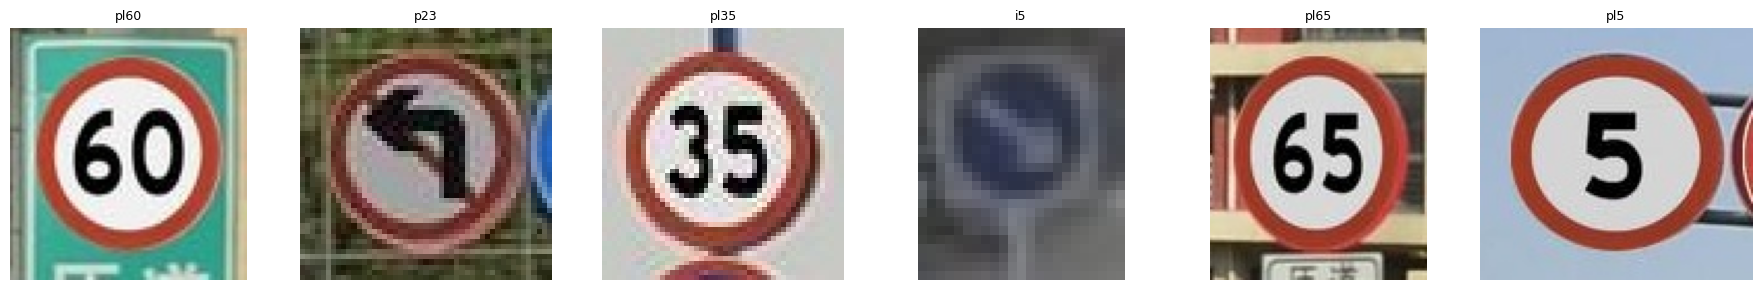

In [9]:
import random
from PIL import Image
import matplotlib.pyplot as plt

counts = {d.name: len(list(d.glob("*.jpg"))) for d in sorted((CROP_ROOT / "train").iterdir())}
sparse = sorted(counts.items(), key=lambda x: x[1])[:10]
print("10 sparsest classes (train crops):")
for name, n in sparse:
    print(f"  {name:6s} {n}")

sample_classes = random.sample(list(counts.keys()), 6)
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, cls in zip(axes, sample_classes):
    img_path = random.choice(list((CROP_ROOT / "train" / cls).glob("*.jpg")))
    ax.imshow(Image.open(img_path))
    ax.set_title(cls, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
print("5 most common classes:", sorted(counts.items(), key=lambda x: -x[1])[:5])

5 most common classes: [('pn', 6914), ('pne', 4024), ('p11', 3541), ('i5', 2540), ('w', 2386)]
